# ACME Talent Insights

**Who this is for:** HR leaders and managers (each section starts with the question and ends with
*what it means*), and engineers (the code shows exactly how each number is produced).

**Where the numbers come from:** the **Gold layer** of the ACME talent data pipeline
(`data/talent-pipeline/job.py`), which ingests HR data from PostgreSQL and learning events from S3,
validates and cleans them (Silver) and builds one curated table per business question (Gold).
This notebook only *reads* data; it never changes it.

| # | Business question | Gold table |
|---|---|---|
| 1 | What are the performance ratings and review history for each employee? | `gold_employee_performance_history` |
| 2 | Which employees have critical skill gaps in key competencies? | `gold_skill_gaps` |
| 3 | Who are the high-potential employees ready for promotion? | `gold_promotion_pipeline` |
| 4 | What training and development has each employee completed? | `gold_employee_learning_summary` |
| 5 | Which employees are at risk of attrition based on performance trends? | `gold_attrition_risk` |
| 6 | How does employee performance correlate with team and project outcomes? | `gold_team_performance_outcomes` |
| 7 | What is the distribution of skills across the organisation? | `gold_skill_distribution` |

**Nothing is typed in.** Every number, every business-rule value (read from the run manifest of the
pipeline run that produced the data) and every direction word (*rose / fell*, *positive / negative*)
is computed when the notebook runs, so it stays correct after the pipeline re-runs on new data.

**How to run:** select the kernel *Python (talent-pipeline)* and *Run All*. Connection settings come
from environment variables (`POSTGRES_*`, `LAKE_BUCKET`, `AWS_*`); if they are not set, the notebook
reads `data/talent-pipeline/env.local`.

## Setup

In [1]:
import ast
import json
import os
import re
import subprocess
import sys
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

pd.set_option("display.max_colwidth", None)   # show full text in tables

for module, package in [("psycopg", "psycopg[binary]"), ("boto3", "boto3"), ("pyarrow", "pyarrow")]:
    try:
        __import__(module)
    except ImportError:   # e.g. the cloud JupyterHub image: install the missing client library once
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", package])
import boto3  # noqa: E402  (imported after the install-if-missing loop above)
import psycopg  # noqa: E402
import pyarrow.parquet as pq  # noqa: E402

# --- Connection settings: environment variables, else env.local (local development) -------
def find_project_file(relative: str) -> Path | None:
    """Locate a file of the talent-pipeline job from the notebook's working directory."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base / relative, base / "data" / "talent-pipeline" / relative):
            if candidate.exists():
                return candidate
    return None

def load_env_file(path: Path) -> None:
    """Set variables from `export KEY=value` lines, without overriding existing ones."""
    for line in path.read_text().splitlines():
        match = re.match(r"\s*export\s+([A-Z_]+)=(.*)", line)
        if match and match.group(1) not in os.environ:
            os.environ[match.group(1)] = os.path.expandvars(match.group(2).strip().strip("'\""))

env_file = find_project_file("env.local")
if "POSTGRES_HOST" not in os.environ and env_file:
    load_env_file(env_file)

def query(sql: str) -> pd.DataFrame:
    """Run a read-only SQL query against the Gold tables in PostgreSQL."""
    with psycopg.connect(
        host=os.environ["POSTGRES_HOST"], port=os.environ.get("POSTGRES_PORT", "5432"),
        dbname=os.environ["POSTGRES_NAME"], user=os.environ["POSTGRES_USER"], password=os.environ["POSTGRES_PASS"],
        sslmode="disable" if os.environ.get("IS_LOCAL", "true") == "true" else "require",
    ) as conn, conn.cursor() as cur:
        cur.execute(sql)
        return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])

GOLD = ["employee_performance_history", "skill_gaps", "promotion_pipeline", "employee_learning_summary",
        "attrition_risk", "team_performance_outcomes", "skill_distribution"]
gold = {name: query(f"SELECT * FROM gold_{name}") for name in GOLD}
gold_run_id = gold["promotion_pipeline"]["_run_id"].iloc[0]
assert all(set(df["_run_id"]) == {gold_run_id} for df in gold.values()), "Gold tables come from different runs"
display(Markdown(f"Loaded **{len(gold)}** Gold tables from `{os.environ['POSTGRES_HOST']}`, all produced by pipeline run "
                 f"`{gold_run_id}`: " + ", ".join(f"{name} ({len(df):,} rows)" for name, df in gold.items())))

Loaded **7** Gold tables from `localhost`, all produced by pipeline run `20261015T064617Z-d31032`: employee_performance_history (4,000 rows), skill_gaps (4,000 rows), promotion_pipeline (2,000 rows), employee_learning_summary (2,000 rows), attrition_risk (2,000 rows), team_performance_outcomes (100 rows), skill_distribution (1,595 rows)

In [2]:
# --- The data lake: run manifest (lineage + business rules) of the run that produced Gold ---------
s3 = boto3.client("s3", endpoint_url=os.environ.get("AWS_ENDPOINT_URL") or None)
BUCKET = os.environ["LAKE_BUCKET"]

def s3_objects(prefix: str) -> list[dict]:
    """All objects under a prefix (key + size)."""
    return [o for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=prefix)
            for o in page.get("Contents", [])]

def read_parquet(prefix: str) -> pd.DataFrame:
    """Read every Parquet file under a lake prefix into one DataFrame."""
    parts = [pq.read_table(BytesIO(s3.get_object(Bucket=BUCKET, Key=o["Key"])["Body"].read())).to_pandas()
             for o in s3_objects(prefix) if o["Key"].endswith(".parquet") and o["Size"] > 0]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

try:
    [manifest_key] = [o["Key"] for o in s3_objects("lineage/runs/") if o["Key"].endswith(f"/{gold_run_id}.json")]
    manifest = json.loads(s3.get_object(Bucket=BUCKET, Key=manifest_key)["Body"].read())
    lake_available = True
except Exception as exc:   # e.g. no S3 access from this environment
    manifest, lake_available = {}, False
    display(Markdown(f"_Data lake not reachable here ({type(exc).__name__}); lineage and data-quality details are skipped._"))

def rules_from_job_source() -> dict:
    """Fallback: read the rule constants straight from job.py (same names, lower-cased)."""
    names = {"CRITICAL_GAP_LEVELS", "HIGH_PERFORMER_RATING", "PROMOTION_MIN_RATING", "LOW_RATING",
             "LEARNING_INACTIVE_DAYS", "RISK_POINTS", "RISK_TIER_HIGH", "RISK_TIER_MEDIUM"}
    tree = ast.parse(find_project_file("job.py").read_text())
    return {t.id.lower(): ast.literal_eval(node.value) for node in tree.body if isinstance(node, ast.Assign)
            for t in node.targets if isinstance(t, ast.Name) and t.id in names}

RULES = manifest.get("business_rules") or rules_from_job_source()
RULES_SOURCE = f"run manifest `{gold_run_id}`" if manifest.get("business_rules") else "`job.py` constants"
P = RULES["risk_points"]
display(Markdown(f"Business rules loaded from the {RULES_SOURCE}: `{json.dumps(RULES)}`"))

# Analysis settings of this notebook (presentation choices, not pipeline rules)
STRONG_PROFICIENCY = 4       # proficiency level >= this counts as "strong" in section 7
DEVELOPING_PROFICIENCY = 2   # proficiency level <= this counts as "developing" in section 7
TOP_N = 15                   # rows shown in shortlists
SHORT_HISTORY_PERIODS = 3    # with this many review periods or fewer, trends are 'latest vs previous'

Business rules loaded from the run manifest `20261015T064617Z-d31032`: `{"critical_gap_levels": 2, "high_performer_rating": 4, "promotion_min_rating": 4, "low_rating": 2, "learning_inactive_days": 180, "risk_points": {"hr_high": 3, "hr_medium": 1, "rating_declined": 2, "low_rating": 1, "learning_inactive": 1}, "risk_tier_high": 4, "risk_tier_medium": 2}`

In [3]:
# --- Chart style: one validated palette, thin marks, hairline solid grid, text in ink colours -----
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE = "#2a78d6", "#eb6834"                                   # categorical slots 1-2
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]  # sequential
STATUS = {"High": "#d03b3b", "Medium": "#fab219"}   # status colours: always shown with a text label
NEUTRAL = "#dddcd7"                                    # "nothing to see" (e.g. Low risk) recedes

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 26,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 10, "font.size": 10, "figure.dpi": 110,
})
BLUE_SCALE = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", BLUES)

def finish(ax, title: str, subtitle: str = "", grid_axis: str = "y") -> None:
    """Title + muted subtitle, grid on the value axis only, gridlines behind the marks."""
    ax.set_title(title)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 8), textcoords="offset points",
                    color=INK_2, fontsize=9.5, va="bottom")
    ax.grid(axis="x" if grid_axis == "y" else "y", visible=False)
    ax.set_axisbelow(True)

def heatmap(ax, frame: pd.DataFrame, fmt: str, xlabels, ylabels, colorbar_label: str | None = None, vmin=None):
    """Sequential one-hue heatmap; cell text is white or ink depending on the cell's darkness."""
    im = ax.imshow(frame.values, cmap=BLUE_SCALE, aspect="auto", vmin=vmin)
    ax.set_xticks(range(frame.shape[1]), xlabels)
    ax.set_yticks(range(frame.shape[0]), ylabels)
    for (i, j), v in np.ndenumerate(frame.values):
        r, g, b, _ = im.cmap(im.norm(v))
        dark = 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.45
        ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=9.5, color="white" if dark else INK)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if colorbar_label:
        ax.figure.colorbar(im, ax=ax, shrink=0.8, label=colorbar_label,
                           format=plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    return im

def finding(text: str) -> None:
    """A highlighted 'what this means' box."""
    display(HTML(f'<div style="border-left:4px solid {BLUE};background:#f3f7fd;padding:10px 14px;'
                 f'margin:6px 0 2px 0;color:{INK};line-height:1.5">{text}</div>'))

def tiles(items) -> None:
    """Stat tiles: a single number is a number, not a chart."""
    html = "".join(
        f'<div style="flex:1;min-width:170px;border:1px solid {GRID};border-radius:8px;padding:12px 14px;background:white">'
        f'<div style="font-size:12px;color:{INK_2}">{label}</div>'
        f'<div style="font-size:26px;font-weight:600;color:{INK};margin:2px 0">{value}</div>'
        f'<div style="font-size:12px;color:{INK_2}">{note}</div></div>' for label, value, note in items)
    display(HTML(f'<div style="display:flex;flex-wrap:wrap;gap:10px">{html}</div>'))

def direction(change: float, up: str = "rose", down: str = "fell", flat: str = "stayed level at", tolerance: float = 0.005) -> str:
    """Pick the right verb for a change instead of assuming its direction."""
    return up if change > tolerance else down if change < -tolerance else flat

def listing(values) -> str:
    """'a', 'a and b', 'a, b and c'."""
    values = [str(v) for v in values]
    return values[0] if len(values) == 1 else ", ".join(values[:-1]) + " and " + values[-1]

## Executive summary

In [4]:
hist, gaps, promo = gold["employee_performance_history"], gold["skill_gaps"], gold["promotion_pipeline"]
learn, risk, teams = gold["employee_learning_summary"], gold["attrition_risk"], gold["team_performance_outcomes"]

periods = sorted(hist["review_period"].unique())
first, last = periods[0], periods[-1]
avg_by_period = hist.groupby("review_period")["rating"].mean()
n_emp = len(promo)
n_candidates = int(promo["is_promotion_candidate"].sum())
n_promote_now = int((promo["pipeline_stage"] == "Promote now").sum())
n_high_risk = int((risk["risk_tier"] == "High").sum())
n_critical = int(gaps["is_critical_gap"].sum())
n_people_critical = gaps.loc[gaps["is_critical_gap"], "employee_id"].nunique()
n_inactive = int((learn["days_since_last_activity"] > RULES["learning_inactive_days"]).sum())
rating_change = avg_by_period[last] - avg_by_period[first]

tiles([
    ("Employees", f"{n_emp:,}", f"{teams.shape[0]} teams, {promo['department'].nunique()} departments"),
    ("Average rating", f"{avg_by_period[last]:.2f}",
     f"{last}; {direction(rating_change, 'up from', 'down from', 'same as')} {avg_by_period[first]:.2f} in {first}"),
    ("Promotion candidates", f"{n_candidates}", f"{n_promote_now} ready now, {n_candidates - n_promote_now} after closing gaps"),
    ("High attrition risk", f"{n_high_risk}", f"{n_high_risk / n_emp:.0%} of employees"),
    ("Critical skill gaps", f"{n_critical}", f"held by {n_people_critical} employees"),
    ("Inactive learners", f"{n_inactive}", f"no learning activity in {RULES['learning_inactive_days']} days"),
])

---
## 1. Performance ratings and review history
*What are the performance ratings and review history for each employee?*

Each employee is reviewed once per half-year period on a 1-5 scale. The pipeline adds the previous rating,
the change and a trend label (improved / stable / declined / first review) to every review.

Review periods in the data: `2024-H2` and `2025-H1` (2 reviews per employee).

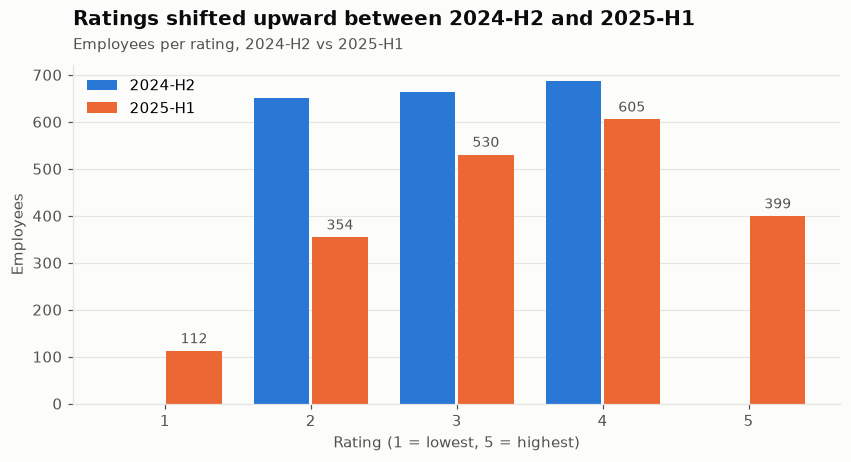

,employees,share
trend into 2025-H1,,
improved,898,45%
stable,872,44%
declined,230,12%


In [5]:
scale = range(int(hist["rating"].min()), int(hist["rating"].max()) + 1)
dist = (hist.pivot_table(index="rating", columns="review_period", values="employee_id", aggfunc="count")
        .reindex(scale).fillna(0).astype(int))
display(Markdown(f"Review periods in the data: {listing(f'`{p}`' for p in periods)} "
                 f"({hist.groupby('employee_id').size().median():.0f} reviews per employee)."))

fig, ax = plt.subplots(figsize=(9, 4))
x, width = np.arange(len(dist.index)), 0.8 / len(periods)
for i, period in enumerate(periods):
    colour = [BLUE, ORANGE][i] if len(periods) <= 2 else BLUE_SCALE((i + 1) / len(periods))
    bars = ax.bar(x + (i - (len(periods) - 1) / 2) * width, dist[period], width * 0.95, color=colour, label=period)
ax.bar_label(bars, padding=3, color=INK_2, fontsize=9)            # label the latest period only
ax.set_xticks(x, [str(r) for r in dist.index])
ax.set_xlabel("Rating (1 = lowest, 5 = highest)")
ax.set_ylabel("Employees")
ax.legend(loc="upper left")
shift = "upward" if rating_change > 0.005 else "downward" if rating_change < -0.005 else "very little"
finish(ax, f"Ratings shifted {shift} between {first} and {last}", f"Employees per rating, {first} vs {last}")
plt.show()

latest = hist[hist["review_period"] == last]
trend = latest["rating_trend"].value_counts().reindex(["improved", "stable", "declined", "first review"]).dropna().astype(int)
display(pd.DataFrame({"employees": trend, "share": (trend / trend.sum()).map("{:.0%}".format)}).rename_axis(f"trend into {last}"))

high = RULES["high_performer_rating"]
high_before = (hist.loc[hist["review_period"] == first, "rating"] >= high).mean()
high_now = (latest["rating"] >= high).mean()
unused = [r for r in range(1, 6) if dist[first].get(r, 0) == 0]
scale_note = (f" In {first} no one was rated {' or '.join(map(str, unused))}: managers used only part of the scale, "
              f"so part of the change may be calibration rather than performance." if unused else "")
headline = {"rose": "Performance improved overall.", "fell": "Performance weakened overall.",
            "stayed level at": "Performance was stable overall."}[direction(rating_change)]
movement = (f"stayed level at {avg_by_period[first]:.2f}" if abs(rating_change) <= 0.005 else
            f"{direction(rating_change)} from {avg_by_period[first]:.2f} to {avg_by_period[last]:.2f}")
finding(f"<b>{headline}</b> The average rating {movement}, and the share of employees "
        f"rated {high} or above went from {high_before:.0%} to {high_now:.0%}. {trend.get('improved', 0):,} employees improved and "
        f"{trend.get('stable', 0):,} held steady, but <b>{trend.get('declined', 0):,} declined</b>; those are the people to "
        f"talk to first (see section 5).{scale_note}")

In [6]:
def review_history(employee_id: int) -> pd.DataFrame:
    """Full review history of one employee (answers 'review history for each employee')."""
    cols = ["full_name", "department", "job_level", "review_period", "rating", "previous_rating", "rating_change",
            "rating_trend", "manager_comment"]
    return hist[hist["employee_id"] == employee_id].sort_values(["period_year", "period_half"])[cols]

example = latest.sort_values("rating_change").iloc[0]["employee_id"]   # the steepest decline, as an example
display(Markdown(f"**Example lookup:** `review_history({example})`"))
review_history(example)

**Example lookup:** `review_history(1956)`

,full_name,department,job_level,review_period,rating,previous_rating,rating_change,rating_trend,manager_comment
3987,Sarah Myers,Human Resources,IC1,2024-H2,4,NaN,NaN,first review,"Solid, consistent contributor this cycle."
3986,Sarah Myers,Human Resources,IC1,2025-H1,2,4.0,-2.0,declined,Missed several key deliverables this cycle; needs support.


---
## 2. Critical skill gaps
*Which employees have critical skill gaps in key competencies?*

For every assessment, **gap = required level - proficiency level** (positive = below what the role needs).

A gap of **2 or more levels is critical** (rule `critical_gap_levels`, from the run manifest `20261015T064617Z-d31032`).

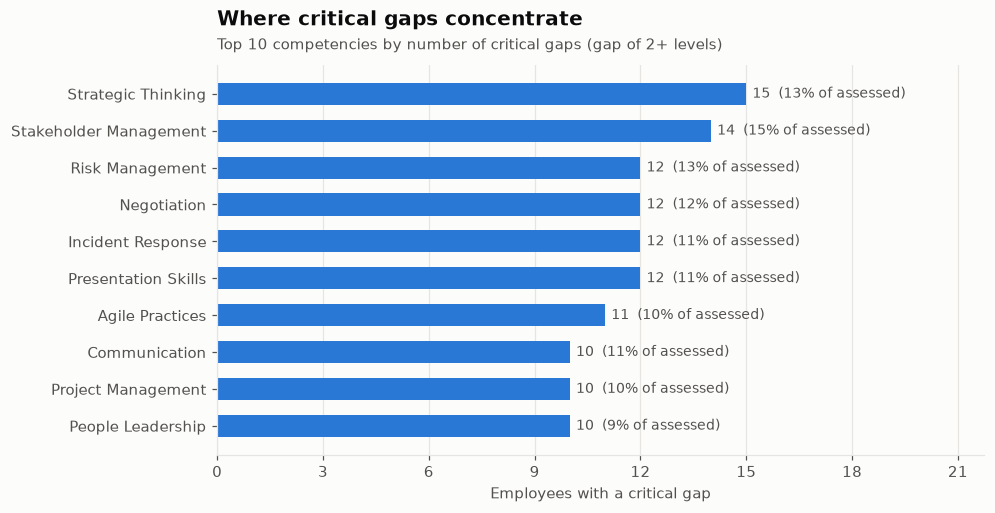

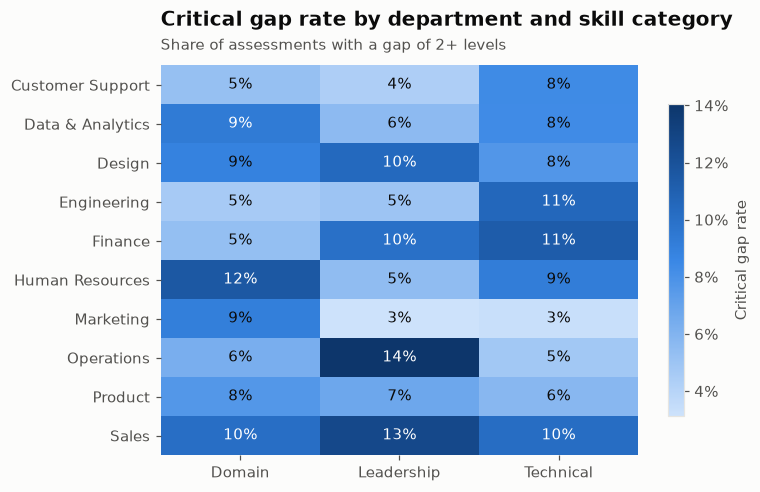

In [7]:
gap_rule = RULES["critical_gap_levels"]
display(Markdown(f"A gap of **{gap_rule} or more levels is critical** (rule `critical_gap_levels`, from the {RULES_SOURCE})."))

by_comp = (gaps.groupby(["competency_name", "category"])
           .agg(assessed=("employee_id", "count"), critical=("is_critical_gap", "sum"))
           .assign(critical_rate=lambda d: d["critical"] / d["assessed"])
           .sort_values(["critical", "critical_rate"], ascending=False).reset_index())
top = by_comp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.barh(top["competency_name"], top["critical"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{c}  ({r:.0%} of assessed)" for c, r in zip(top["critical"], top["critical_rate"], strict=True)],
             padding=4, color=INK_2, fontsize=9)
ax.set_xlabel("Employees with a critical gap")
ax.set_xlim(0, top["critical"].max() * 1.45)
ax.xaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=True))
finish(ax, "Where critical gaps concentrate",
       f"Top {len(top)} competencies by number of critical gaps (gap of {gap_rule}+ levels)", grid_axis="x")
plt.show()

dept_cat = gaps.pivot_table(index="department", columns="category", values="is_critical_gap", aggfunc="mean")
fig, ax = plt.subplots(figsize=(7, 4.6))
heatmap(ax, dept_cat, ".0%", dept_cat.columns, dept_cat.index, colorbar_label="Critical gap rate")
finish(ax, "Critical gap rate by department and skill category", f"Share of assessments with a gap of {gap_rule}+ levels",
       grid_axis="none")
plt.show()

In [8]:
people = (gaps[gaps["is_critical_gap"]].groupby(["employee_id", "full_name", "department", "job_level"])
          .agg(critical_gaps=("competency_name", "count"), competencies=("competency_name", lambda s: ", ".join(sorted(s))),
               largest_gap=("gap", "max"))
          .reset_index().sort_values(["critical_gaps", "largest_gap"], ascending=False))
display(Markdown(f"**Employees with critical gaps** ({len(people)} people; top {TOP_N} shown):"))
display(people.head(TOP_N).reset_index(drop=True))

top_comp = by_comp.iloc[0]
worst_cell = dept_cat.stack().idxmax()
category_rates = dept_cat.mean().sort_values(ascending=False)
category_spread = category_rates.max() - category_rates.min()
category_text = ", ".join(f"{c} {v:.0%}" for c, v in category_rates.items())
category_note = (f"Rates are similar across categories ({category_text} on average), so training should target specific "
                 f"competencies rather than whole categories."
                 if category_spread < 0.03 else
                 f"<b>{category_rates.index[0]}</b> skills stand out ({category_text} on average), so start there.")
finding(f"<b>{n_critical} critical gaps across {n_people_critical} employees</b> ({n_people_critical / n_emp:.0%} of the "
        f"workforce). The largest concentration is in <b>{top_comp['competency_name']}</b> ({top_comp['category']}, "
        f"{int(top_comp['critical'])} people), and the highest rate is <b>{worst_cell[1]}</b> skills in "
        f"<b>{worst_cell[0]}</b> ({dept_cat.stack().max():.0%}). {category_note}")

**Employees with critical gaps** (317 people; top 15 shown):

,employee_id,full_name,department,job_level,critical_gaps,competencies,largest_gap
0,108,Mark Lewis,Finance,IC3,2,"Market Analysis, Negotiation",2
1,410,Laurie Nunez,Product,Senior IC,2,"Communication, Risk Management",2
2,430,Isabella Baker,Sales,IC2,2,"Incident Response, Onboarding & Enablement",2
3,505,Carrie Duncan,Human Resources,IC3,2,"Technical Writing, Test Automation",2
4,895,Jesus White,Engineering,IC3,2,"Customer Empathy, Public Speaking",2
5,1225,Amy Tucker,Marketing,IC1,2,"Market Analysis, Project Management",2
6,1387,Paul Cole,Sales,IC3,2,"Conflict Resolution, Financial Acumen",2
7,1680,Kaylee Grimes,Operations,Director,2,"Coaching & Mentoring, Risk Management",2
8,2,Kristie Heath,Sales,Director,1,Strategic Thinking,2
9,5,Linda Murray,Sales,IC1,1,Machine Learning,2


---
## 3. High-potential employees ready for promotion
*Who are the high-potential employees ready for promotion?*

Candidates with a critical skill gap are flagged *Promote after closing skill gaps*. The grid below is a
**9-box style view**: potential (talent review) against performance (latest rating).

**Promotion candidate** = potential *High* + readiness *Ready Now* + latest rating **4 or above** (rule `promotion_min_rating`, from the run manifest `20261015T064617Z-d31032`).

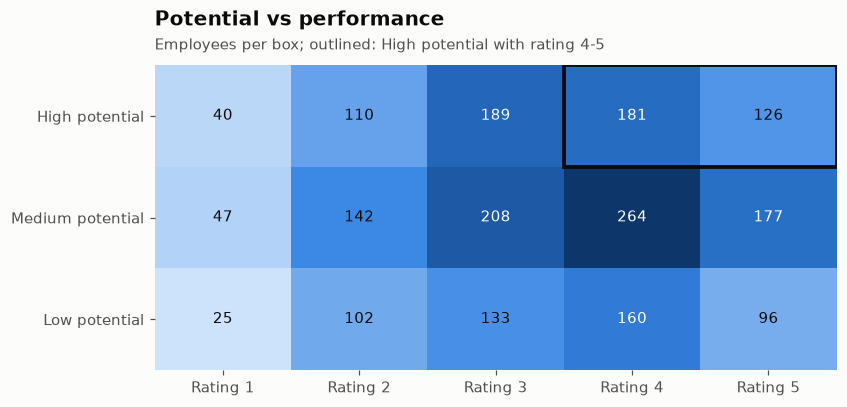

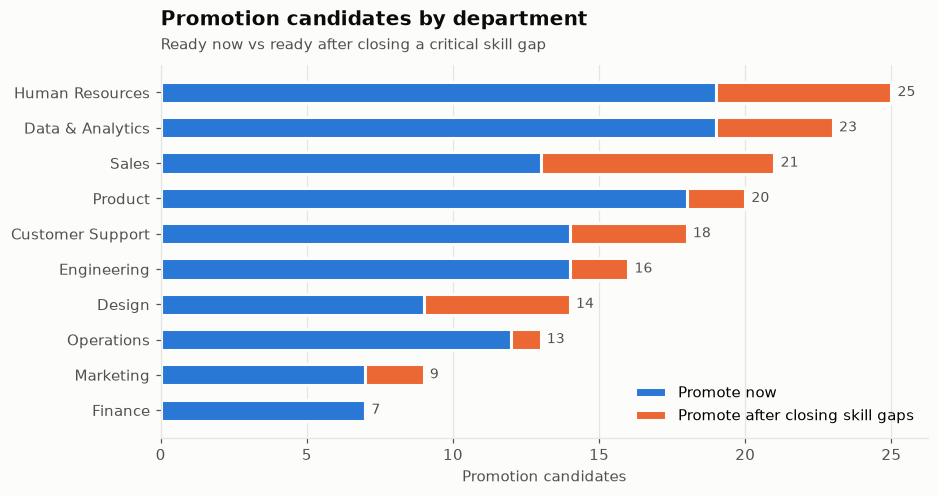

In [9]:
min_rating = RULES["promotion_min_rating"]
display(Markdown(f"**Promotion candidate** = potential *High* + readiness *Ready Now* + latest rating **{min_rating} or above** "
                 f"(rule `promotion_min_rating`, from the {RULES_SOURCE})."))

ratings = list(range(int(promo["latest_rating"].min()), int(promo["latest_rating"].max()) + 1))
grid = (promo.pivot_table(index="potential_rating", columns="latest_rating", values="employee_id", aggfunc="count")
        .reindex(index=["High", "Medium", "Low"], columns=ratings, fill_value=0).fillna(0).astype(int))
fig, ax = plt.subplots(figsize=(8, 3.6))
heatmap(ax, grid, "d", [f"Rating {r}" for r in ratings], [f"{p} potential" for p in grid.index])
zone_start = ratings.index(min_rating)
ax.add_patch(plt.Rectangle((zone_start - 0.5, -0.5), len(ratings) - zone_start, 1, fill=False, edgecolor=INK, linewidth=2.5))
finish(ax, "Potential vs performance",
       f"Employees per box; outlined: High potential with rating {min_rating}-{ratings[-1]}", grid_axis="none")
plt.show()

stage_order = ["Promote now", "Promote after closing skill gaps"]
by_dept = (promo[promo["is_promotion_candidate"]]
           .pivot_table(index="department", columns="pipeline_stage", values="employee_id", aggfunc="count", fill_value=0)
           .reindex(columns=stage_order, fill_value=0).assign(total=lambda d: d.sum(axis=1)).sort_values("total"))
fig, ax = plt.subplots(figsize=(9, 4.4))
left = np.zeros(len(by_dept))
for stage, colour in zip(stage_order, [BLUE, ORANGE], strict=True):
    ax.barh(by_dept.index, by_dept[stage], left=left, color=colour, height=0.6, label=stage, edgecolor=SURFACE, linewidth=2)
    left += by_dept[stage].values
ax.bar_label(ax.containers[-1], labels=by_dept["total"], padding=4, color=INK_2, fontsize=9)
ax.set_xlabel("Promotion candidates")
ax.legend(loc="lower right")
finish(ax, "Promotion candidates by department", "Ready now vs ready after closing a critical skill gap", grid_axis="x")
plt.show()

In [10]:
cols = ["full_name", "department", "job_level", "tenure_years", "latest_rating", "avg_rating", "rating_trend",
        "critical_gap_count", "certifications_earned", "pipeline_stage"]
shortlist = promo[promo["is_promotion_candidate"]].sort_values(
    ["critical_gap_count", "latest_rating", "avg_rating", "certifications_earned"], ascending=[True, False, False, False])
display(Markdown(f"**Promotion shortlist** ({len(shortlist)} candidates; top {TOP_N} shown):"))
display(shortlist[cols].head(TOP_N).reset_index(drop=True))

high_pot = promo[promo["potential_rating"] == "High"]
below_bar = int((high_pot["latest_rating"] < min_rating).sum())
corr = promo["latest_rating"].corr(promo["potential_rating"].map({"Low": 1, "Medium": 2, "High": 3}))
relation = ("almost unrelated" if abs(corr) < 0.1 else "weakly related" if abs(corr) < 0.3
            else "moderately related" if abs(corr) < 0.6 else "strongly related")
leaders = listing(f"{d} ({n})" for d, n in by_dept["total"].sort_values(ascending=False).head(3).items())
finding(f"<b>{n_candidates} employees are promotion candidates</b>: {n_promote_now} can be promoted now and "
        f"{n_candidates - n_promote_now} after closing a critical skill gap. Leading departments: {leaders}. "
        f"Potential and performance are <b>{relation}</b> (correlation {corr:.2f}): <b>{below_bar} of {len(high_pot)} "
        f"high-potential employees are rated below {min_rating}</b>."
        + (" Either the potential ratings need calibration, or these people need support to turn potential into performance."
           if abs(corr) < 0.3 else ""))

**Promotion shortlist** (166 candidates; top 15 shown):

,full_name,department,job_level,tenure_years,latest_rating,avg_rating,rating_trend,critical_gap_count,certifications_earned,pipeline_stage
0,Yolanda Foley,Marketing,IC2,3.4,5,4.5,improved,0,3,Promote now
1,Melissa Anderson,Design,IC2,6.4,5,4.5,improved,0,3,Promote now
2,Sarah Rivera,Sales,Senior Manager,5.5,5,4.5,improved,0,3,Promote now
3,Daniel Osborne,Customer Support,Manager,5.8,5,4.5,improved,0,2,Promote now
4,Lisa Johnson,Product,Manager,2.8,5,4.5,improved,0,2,Promote now
5,Barbara Lozano,Product,IC1,2.4,5,4.5,improved,0,2,Promote now
6,Lindsey Gonzales,Customer Support,Senior Manager,5.4,5,4.5,improved,0,1,Promote now
7,Michael Stein,Operations,Director,3.7,5,4.5,improved,0,1,Promote now
8,Cathy Jackson,Design,Director,1.2,5,4.5,improved,0,1,Promote now
9,Patrick Harris,Product,Senior Manager,4.5,5,4.5,improved,0,1,Promote now


---
## 4. Training and development completed
*What training and development activities have been completed by each employee?*

From the learning platform's event feed (enrolments, modules, quizzes, completions, certifications).
**Completion rate = courses completed / courses engaged with** (any event for the course), because the
feed is not a strict funnel (see *Data quality*).

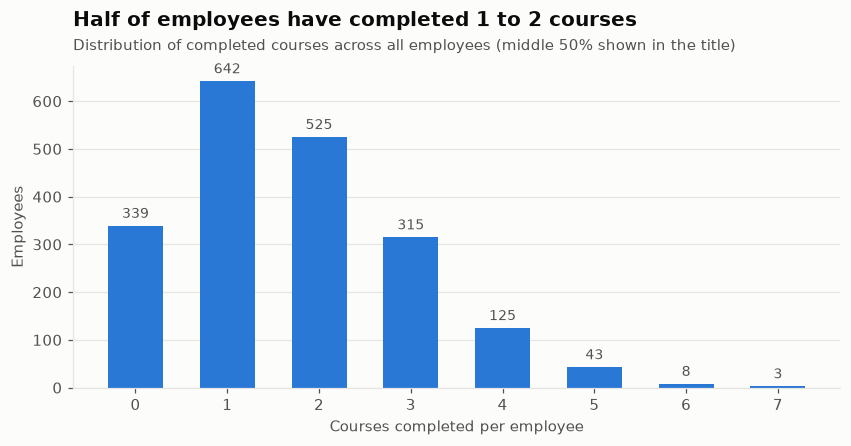

**Learning by department:**

,employees,avg_courses_completed,avg_certifications,avg_completion_rate,avg_quiz_score,inactive_180d
department,,,,,,
Product,211,1.85,0.88,0.14,64.77,33
Finance,93,1.85,0.77,0.15,66.59,14
Sales,241,1.84,0.97,0.14,67.12,30
Data & Analytics,274,1.81,0.83,0.15,67.63,45
Engineering,148,1.77,0.93,0.15,67.05,22
Design,188,1.72,0.79,0.14,67.77,27
Marketing,122,1.65,0.95,0.14,68.04,20
Operations,187,1.59,0.84,0.12,67.61,34
Human Resources,327,1.58,0.88,0.13,67.59,47


In [11]:
inactive_days = RULES["learning_inactive_days"]
fig, ax = plt.subplots(figsize=(9, 3.8))
counts = learn["courses_completed"].value_counts().sort_index()
bars = ax.bar(counts.index, counts.values, color=BLUE, width=0.6)
ax.bar_label(bars, padding=3, color=INK_2, fontsize=9)
ax.set_xticks(counts.index)
ax.set_xlabel("Courses completed per employee")
ax.set_ylabel("Employees")
q1, q3 = learn["courses_completed"].quantile([0.25, 0.75]).astype(int)
finish(ax, f"Half of employees have completed {q1} to {q3} courses" if q1 != q3 else f"Most employees have completed {q1} courses",
       "Distribution of completed courses across all employees (middle 50% shown in the title)")
plt.show()

dept_learn = learn.groupby("department").agg(
    employees=("employee_id", "count"), avg_courses_completed=("courses_completed", "mean"),
    avg_certifications=("certifications_earned", "mean"), avg_completion_rate=("completion_rate", "mean"),
    avg_quiz_score=("avg_quiz_score", "mean"),
    **{f"inactive_{inactive_days}d": ("days_since_last_activity", lambda s: int((s > inactive_days).sum()))},
).round(2).sort_values("avg_courses_completed", ascending=False)
display(Markdown("**Learning by department:**"))
display(dept_learn)

In [12]:
def training_record(employee_id: int) -> pd.Series:
    """Completed courses and learning stats for one employee."""
    cols = ["full_name", "department", "courses_completed", "completed_courses", "certifications_earned",
            "quizzes_passed", "avg_quiz_score", "completion_rate", "last_activity_date", "days_since_last_activity"]
    return learn.set_index("employee_id").loc[employee_id, cols]

most = learn.sort_values(["courses_completed", "certifications_earned"], ascending=False).iloc[0]
display(Markdown(f"**Example lookup:** `training_record({most['employee_id']})`"))
display(training_record(most["employee_id"]))

dept_range = dept_learn["avg_courses_completed"]
dept_note = ("Departments differ little" if dept_range.max() - dept_range.min() < 0.5 else "Departments differ noticeably")
finding(f"Employees completed <b>{learn['courses_completed'].mean():.1f} courses</b> and earned "
        f"<b>{learn['certifications_earned'].mean():.1f} certifications</b> on average, with an average quiz score of "
        f"{learn['avg_quiz_score'].mean():.0f}. <b>{n_inactive} employees ({n_inactive / n_emp:.0%}) have had no learning activity "
        f"in the last {inactive_days} days</b>; they are a re-engagement target and one input to the attrition score. "
        f"{dept_note} (from {dept_range.min():.2f} to {dept_range.max():.2f} courses per person).")

**Example lookup:** `training_record(987)`

full_name                                                                                                                                                                                                                      Bryan Ware
department                                                                                                                                                                                                                          Sales
courses_completed                                                                                                                                                                                                                       7
completed_courses           [Dimensional Data Modeling, Effective Decision Making, New Hire Onboarding Enablement, Project Management Fundamentals, Resolving Team Conflict, Test Automation Bootcamp, Time Management for Professionals]
certifications_earned                                           

---
## 5. Attrition risk
*Which employees are at risk of attrition based on performance trends?*

An **explainable score**, not a black box: each factor adds points and is listed as a reason.

Points: HR flagged High **+3** or Medium **+1**, rating declined since the last review **+2**, latest rating 2 or below **+1**, no learning activity in 180 days **+1**. **High risk = 4+ points**, Medium = 2-3, Low = below 2 (rules from the run manifest `20261015T064617Z-d31032`).

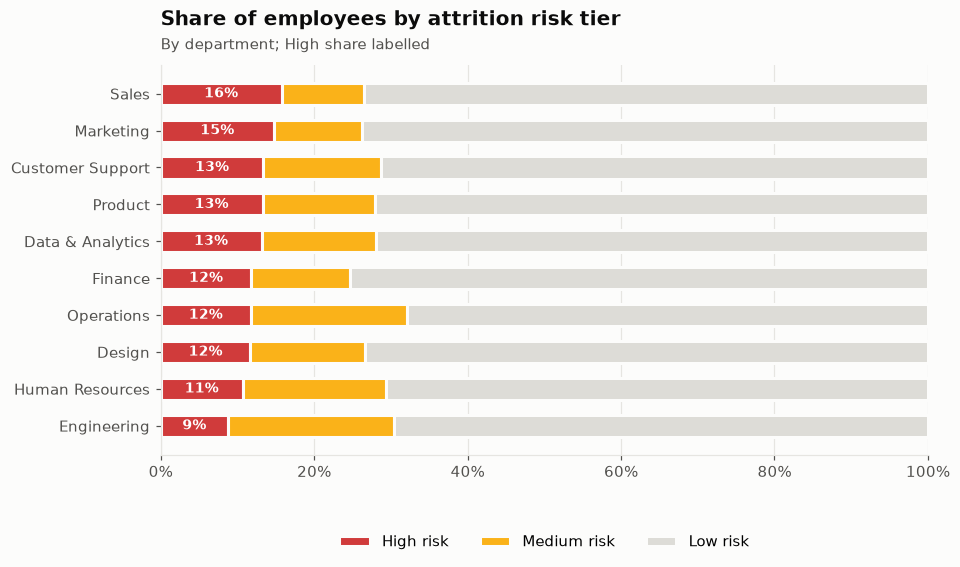

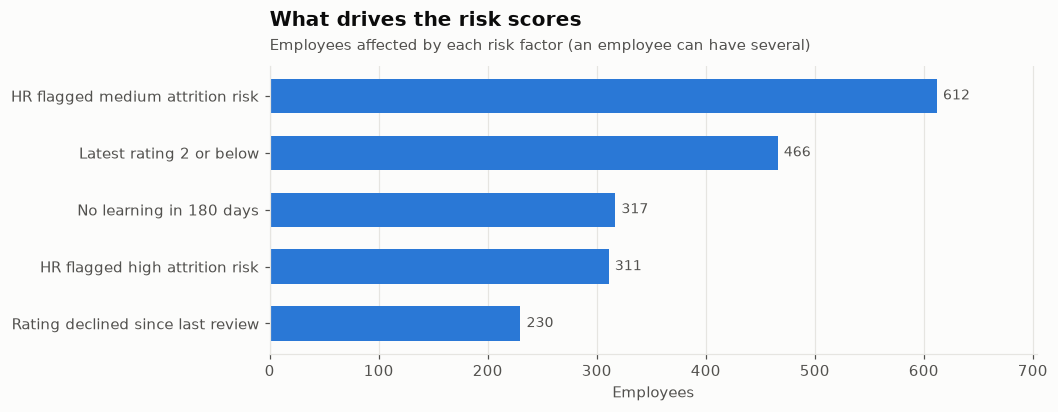

In [13]:
display(Markdown(
    f"Points: HR flagged High **+{P['hr_high']}** or Medium **+{P['hr_medium']}**, rating declined since the last review "
    f"**+{P['rating_declined']}**, latest rating {RULES['low_rating']} or below **+{P['low_rating']}**, no learning activity in "
    f"{RULES['learning_inactive_days']} days **+{P['learning_inactive']}**. **High risk = {RULES['risk_tier_high']}+ points**, "
    f"Medium = {RULES['risk_tier_medium']}-{RULES['risk_tier_high'] - 1}, Low = below {RULES['risk_tier_medium']} "
    f"(rules from the {RULES_SOURCE})."))

tier_order = ["High", "Medium", "Low"]
share = (pd.crosstab(risk["department"], risk["risk_tier"], normalize="index")
         .reindex(columns=tier_order, fill_value=0).sort_values("High"))
fig, ax = plt.subplots(figsize=(9, 4.6))
left = np.zeros(len(share))
for tier in tier_order:
    ax.barh(share.index, share[tier], left=left, color=STATUS.get(tier, NEUTRAL), height=0.6, label=f"{tier} risk",
            edgecolor=SURFACE, linewidth=2)
    left += share[tier].values
for y, v in enumerate(share["High"]):
    ax.text(v / 2, y, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlim(0, 1)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.28), ncol=3)
finish(ax, "Share of employees by attrition risk tier", "By department; High share labelled", grid_axis="x")
plt.show()

def factor_group(reason: str) -> str:
    """Group the per-employee reason texts into the scoring factors."""
    if reason.startswith("Rating declined"):
        return "Rating declined since last review"
    if reason.startswith("Low latest rating"):
        return f"Latest rating {RULES['low_rating']} or below"
    if reason.startswith("No learning activity"):
        return f"No learning in {RULES['learning_inactive_days']} days"
    return reason

factors = risk.explode("risk_factors").dropna(subset=["risk_factors"])
factor_counts = factors.assign(group=factors["risk_factors"].map(factor_group))["group"].value_counts().iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.barh(factor_counts.index, factor_counts.values, color=BLUE, height=0.6)
ax.bar_label(bars, padding=4, color=INK_2, fontsize=9)
ax.set_xlim(0, factor_counts.max() * 1.15)
ax.set_xlabel("Employees")
finish(ax, "What drives the risk scores", "Employees affected by each risk factor (an employee can have several)", grid_axis="x")
plt.show()

In [14]:
watch = risk[risk["risk_tier"] == "High"].sort_values(["risk_score", "latest_rating"], ascending=[False, True])
watch_view = watch.assign(reasons=watch["risk_factors"].map("; ".join))[
    ["full_name", "department", "job_level", "potential_rating", "latest_rating", "previous_rating", "risk_score", "reasons"]]
display(Markdown(f"**Attrition watch list** ({len(watch)} high-risk employees; top {TOP_N} shown):"))
display(watch_view.head(TOP_N).reset_index(drop=True))

hp_at_risk = int(((risk["risk_tier"] == "High") & (risk["potential_rating"] == "High")).sum())
declined_high = int(((risk["risk_tier"] == "High") & (risk["rating_trend"] == "declined")).sum())
spread = share["High"].max() - share["High"].min()
spread_note = (f"Risk is spread fairly evenly across departments ({share['High'].min():.0%}-{share['High'].max():.0%}), so this "
               f"is an organisation-wide issue rather than one team's."
               if spread < 0.10 else
               f"Risk is concentrated: <b>{share['High'].idxmax()}</b> has the highest share ({share['High'].max():.0%}) versus "
               f"{share['High'].min():.0%} in {share['High'].idxmin()}.")
finding(f"<b>{n_high_risk} employees ({n_high_risk / n_emp:.0%}) are high risk</b>, with "
        f"{int((risk['risk_tier'] == 'Medium').sum())} more at medium risk. {declined_high} of the high-risk group also saw "
        f"their rating fall, the clearest performance-trend signal. <b>{hp_at_risk} high-risk employees are rated High "
        f"potential</b>: losing them would also shrink the promotion pipeline, so they should get retention conversations "
        f"first. {spread_note}")

**Attrition watch list** (251 high-risk employees; top 15 shown):

,full_name,department,job_level,potential_rating,latest_rating,previous_rating,risk_score,reasons
0,Paula Davies,Product,Manager,High,1,3,7,HR flagged high attrition risk; Rating declined 3 -> 1; Low latest rating (1); No learning activity in 180 days
1,Glenn Mathis,Human Resources,IC3,High,1,2,7,HR flagged high attrition risk; Rating declined 2 -> 1; Low latest rating (1); No learning activity in 180 days
2,Alexandra Lee,Operations,IC3,High,1,3,7,HR flagged high attrition risk; Rating declined 3 -> 1; Low latest rating (1); No learning activity in 180 days
3,Brian Brock,Finance,Director,Medium,1,2,7,HR flagged high attrition risk; Rating declined 2 -> 1; Low latest rating (1); No learning activity in 180 days
4,Nicole Smith,Customer Support,Senior IC,Medium,1,3,7,HR flagged high attrition risk; Rating declined 3 -> 1; Low latest rating (1); No learning activity in 180 days
5,Crystal Logan,Marketing,Director,Medium,1,3,7,HR flagged high attrition risk; Rating declined 3 -> 1; Low latest rating (1); No learning activity in 180 days
6,Joseph Ford,Design,IC3,Low,1,2,7,HR flagged high attrition risk; Rating declined 2 -> 1; Low latest rating (1); No learning activity in 180 days
7,Amy Tucker,Marketing,IC1,High,1,2,7,HR flagged high attrition risk; Rating declined 2 -> 1; Low latest rating (1); No learning activity in 180 days
8,David Mcclure,Human Resources,IC3,High,1,2,7,HR flagged high attrition risk; Rating declined 2 -> 1; Low latest rating (1); No learning activity in 180 days
9,Rodney Wilkerson,Customer Support,Senior IC,Medium,2,3,7,HR flagged high attrition risk; Rating declined 3 -> 2; Low latest rating (2); No learning activity in 180 days


---
## 6. Performance vs team and project outcomes
*How does employee performance correlate with team and project outcomes?*

One point per team that delivered projects: the team's average latest rating against its average project
outcome score. Only teams with projects can be compared.

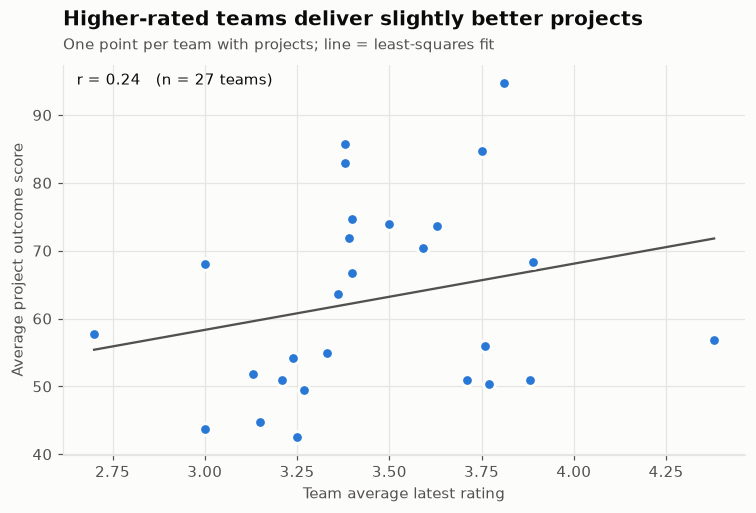

,teams,avg_latest_rating,high_performer_share,avg_outcome_score
project_health,,,,
no troubled project,27,3.45,0.51,62.76


In [15]:
with_projects = teams[teams["has_projects"]].copy()
r = with_projects["avg_latest_rating"].corr(with_projects["avg_outcome_score"])
slope, intercept = np.polyfit(with_projects["avg_latest_rating"], with_projects["avg_outcome_score"], 1)
strength = "weak" if abs(r) < 0.3 else "moderate" if abs(r) < 0.6 else "strong"
sign = "positive" if r > 0 else "negative"
title = {("positive", "weak"): "Higher-rated teams deliver slightly better projects",
         ("negative", "weak"): "Higher-rated teams deliver slightly worse projects"}.get(
             (sign, strength), f"Team ratings and project outcomes: {strength} {sign} relationship")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(with_projects["avg_latest_rating"], with_projects["avg_outcome_score"], s=60, color=BLUE,
           edgecolor=SURFACE, linewidth=2, zorder=3)
xs = np.linspace(with_projects["avg_latest_rating"].min(), with_projects["avg_latest_rating"].max(), 50)
ax.plot(xs, slope * xs + intercept, color=INK_2, linewidth=1.5, zorder=2)
ax.text(0.02, 0.95, f"r = {r:.2f}   (n = {len(with_projects)} teams)", transform=ax.transAxes, color=INK, fontsize=10)
ax.set_xlabel("Team average latest rating")
ax.set_ylabel("Average project outcome score")
finish(ax, title, "One point per team with projects; line = least-squares fit", grid_axis="both")
ax.grid(True)
plt.show()

status_view = (with_projects.assign(project_health=np.where(with_projects["troubled_projects"] > 0,
                                                            "has at-risk/cancelled project", "no troubled project"))
               .groupby("project_health")
               .agg(teams=("team_id", "count"), avg_latest_rating=("avg_latest_rating", "mean"),
                    high_performer_share=("high_performer_share", "mean"), avg_outcome_score=("avg_outcome_score", "mean"))
               .round(2))
display(status_view)

In [16]:
small_sample = len(with_projects) < 30
finding(f"The relationship is <b>{strength} and {sign} (r = {r:.2f})</b>: teams with higher average ratings tend to score "
        f"{'better' if slope > 0 else 'worse'} on projects (about {abs(slope):.0f} outcome points per rating point), and ratings "
        f"explain ~{r ** 2:.0%} of the variation. <b>Only {len(with_projects)} of {len(teams)} teams have projects</b>"
        + (", so this is indicative, not conclusive. Recommendation: link more projects to teams in the source system "
           "before using this for decisions." if small_sample else "."))

---
## 7. Distribution of skills across the organisation
*What is the distribution of skills across the organisation?*

Proficiency levels from competency assessments, by skill category and by competency.

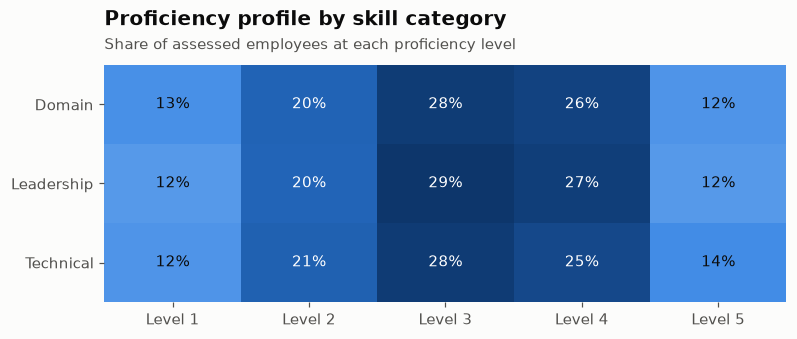

**Weakest five and strongest five competencies** (by average proficiency):

,,assessed,avg_proficiency,avg_required,share_strong
competency_name,category,,,,
Stakeholder Management,Domain,92,2.62,2.84,0.24
Negotiation,Domain,103,2.80,2.98,0.27
Risk Management,Domain,94,2.87,3.00,0.37
DevOps Practices,Technical,86,2.88,2.87,0.34
Market Analysis,Domain,99,2.91,2.85,0.34
API Design,Technical,107,3.18,3.05,0.44
Pricing Strategy,Domain,95,3.19,3.16,0.40
Cloud Architecture,Technical,102,3.20,3.11,0.44
Localization,Domain,109,3.27,3.08,0.53


In [17]:
skill_dist = gold["skill_distribution"]
cat_level = skill_dist.pivot_table(index="category", columns="proficiency_level", values="employees", aggfunc="sum").fillna(0)
cat_share = cat_level.div(cat_level.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8, 2.8))
heatmap(ax, cat_share, ".0%", [f"Level {c}" for c in cat_share.columns], cat_share.index, vmin=0)
finish(ax, "Proficiency profile by skill category", "Share of assessed employees at each proficiency level", grid_axis="none")
plt.show()

comp = (gaps.groupby(["competency_name", "category"])
        .agg(assessed=("employee_id", "count"), avg_proficiency=("proficiency_level", "mean"),
             avg_required=("required_level", "mean"),
             share_strong=("proficiency_level", lambda s: (s >= STRONG_PROFICIENCY).mean()))
        .round(2).sort_values("avg_proficiency"))
display(Markdown("**Weakest five and strongest five competencies** (by average proficiency):"))
display(pd.concat([comp.head(5), comp.tail(5)]))

In [18]:
total = cat_level.values.sum()
strong = cat_level[[c for c in cat_level.columns if c >= STRONG_PROFICIENCY]].sum().sum() / total
developing = cat_level[[c for c in cat_level.columns if c <= DEVELOPING_PROFICIENCY]].sum().sum() / total
profile_gap = (cat_share - cat_share.mean()).abs().max().max()
balance = "broadly balanced" if abs(strong - developing) < 0.10 else ("strong overall" if strong > developing else "still developing")
similar = (f"with similar profiles across {listing(cat_share.index)}" if profile_gap < 0.05
           else "with clear differences between categories (see the heatmap)")
finding(f"Skills are <b>{balance}</b>: {strong:.0%} of assessments are at level {STRONG_PROFICIENCY}+ (strong) and "
        f"{developing:.0%} at level {DEVELOPING_PROFICIENCY} or below (developing), {similar}. The weakest competency is "
        f"<b>{comp.index[0][0]}</b> (average {comp.iloc[0]['avg_proficiency']:.2f}) and the strongest <b>{comp.index[-1][0]}</b> "
        f"({comp.iloc[-1]['avg_proficiency']:.2f}). Each competency is assessed for a median of "
        f"{comp['assessed'].median():.0f} employees, so the organisation-wide picture is a sample, not a full skills inventory.")

---
## Data quality and lineage
How trustworthy are these numbers? Every run records what came in, what was kept, what was quarantined
(with the reason) and what was removed as a duplicate. Everything below is read from the data lake for the
pipeline run that produced the Gold tables above.

In [19]:
if lake_available:
    run_date = manifest["run_date"]
    datasets = {(d["layer"], d["dataset"]): d for d in manifest["datasets"]}
    recon = pd.DataFrame(manifest["datasets"]).query("layer != 'gold'")[
        ["layer", "dataset", "rows_in", "rows_out", "rows_rejected", "rows_dropped"]]
    display(Markdown(f"**Reconciliation, run `{manifest['run_id']}`** ({manifest['status']}, run date {run_date}, "
                     f"{manifest['duration_seconds']:.0f} s): rows_in = rows_out + rows_rejected (quarantined) + "
                     f"rows_dropped (duplicates)"))
    display(recon.reset_index(drop=True))

**Reconciliation, run `20261015T064617Z-d31032`** (SUCCEEDED, run date 2026-10-15, 69 s): rows_in = rows_out + rows_rejected (quarantined) + rows_dropped (duplicates)

,layer,dataset,rows_in,rows_out,rows_rejected,rows_dropped
0,bronze,teams,100,100,0,0
1,bronze,competencies,40,40,0,0
2,bronze,employees,2000,2000,0,0
3,bronze,projects,33,33,0,0
4,bronze,performance_reviews,4000,4000,0,0
5,bronze,competency_assessments,4000,4000,0,0
6,bronze,talent_review,2000,2000,0,0
7,bronze,learning_activity,29868,29868,0,0
8,silver,teams,100,100,0,0
9,silver,competencies,40,40,0,0


In [20]:
if lake_available:
    landing = [o for o in s3_objects("landing/learning_activity/") if o["Key"].endswith(".jsonl")]
    empty_days = ["-".join(re.findall(r"(?:year|month|day)=(\d+)", o["Key"])) for o in landing if o["Size"] == 0]
    bronze_events = read_parquet(f"bronze/learning_activity/ingest_date={run_date}/")
    quarantine = read_parquet(f"quarantine/learning_activity/run_date={run_date}/")
    silver_events = read_parquet("silver/learning_activity/")

    def problem(row) -> str:
        """Group a quarantine reason into a readable problem category."""
        if row["_dq_stage"] == "partition":
            return "Event date does not match its daily folder"
        if row["_dq_stage"] == "referential":
            return "Unknown employee (no matching employee record)"
        if row["_dq_errors"].startswith("malformed JSON"):
            return "Truncated / malformed JSON line"
        field = row["_dq_errors"].split(":")[0]
        return {"employee_id": "Missing or invalid employee_id",
                "event_date": "Unparseable or impossible event date"}.get(field, f"Invalid {field}")

    def raw_value(raw: str, field: str):
        """A field's original value from a quarantined record (None if the record isn't valid JSON)."""
        try:
            return json.loads(raw).get(field)
        except (TypeError, ValueError, AttributeError):
            return None

    quarantine["problem"] = quarantine.apply(problem, axis=1)
    quarantine["event_id"] = quarantine["_dq_raw"].map(lambda raw: raw_value(raw, "event_id"))
    bad_dates = quarantine.loc[quarantine["problem"].str.startswith("Unparseable"), "_dq_raw"].map(
        lambda raw: raw_value(raw, "event_date"))
    examples = {"Unparseable or impossible event date": "e.g. " + ", ".join(f"'{v}'" for v in sorted(set(map(str, bad_dates))))}

    renamed = int(bronze_events["raw_line"].str.contains('"notes"\\s*:', regex=True).sum())
    duplicates_removed = datasets[("silver", "learning_activity")]["rows_dropped"]
    duplicated_and_invalid = int(quarantine["event_id"].dropna().duplicated().sum())
    course_events = silver_events.groupby(["employee_id", "course_name"])["event_type"].agg(set)
    no_enrolment = int(sum("course_completed" in s and "enrollment" not in s for s in course_events))
    hr_tables = [d for (layer, name), d in datasets.items() if layer == "silver" and name != "learning_activity"]

    rows = [("Empty daily file(s)", len(empty_days), ", ".join(empty_days) or "-",
             "Warning in Bronze (possible export failure upstream)")]
    for name, n in quarantine["problem"].value_counts().items():
        rows.append((name, int(n), examples.get(name, "-"), "Quarantined with reason"))
    rows += [
        ("Duplicate events (same event_id), extra copies", duplicates_removed, "-", "Removed; one copy kept"),
        ("Duplicated events that were also invalid", duplicated_and_invalid, "-", "All copies quarantined"),
        ("Field renamed by the producer ('notes' instead of 'text')", renamed, "-", "Renamed and kept (schema-drift warning)"),
        ("Course completions without an enrolment event", no_enrolment, "-",
         "Kept; completion rate uses courses engaged as denominator"),
    ]
    issues = pd.DataFrame(rows, columns=["issue (learning event feed)", "count", "details", "handling"])
    display(Markdown("**Data-quality issues found in the source data and how the pipeline handled them**"))
    display(issues[issues["count"] > 0].reset_index(drop=True))

    hr_rejected = sum(d["rows_rejected"] + d["rows_dropped"] for d in hr_tables)
    finding(f"The learning feed delivered {datasets[('bronze', 'learning_activity')]['rows_in']:,} lines: "
            f"{datasets[('silver', 'learning_activity')]['rows_out']:,} were kept, {len(quarantine):,} quarantined with a reason "
            f"and {duplicates_removed:,} duplicates removed. "
            + (f"The {len(hr_tables)} HR tables passed every check (types, ranges, allowed values, keys, references) "
               f"with zero rejects." if hr_rejected == 0 else
               f"The HR tables had {hr_rejected:,} rejected or duplicate rows (see the reconciliation table)."))

**Data-quality issues found in the source data and how the pipeline handled them**

,issue (learning event feed),count,details,handling
0,Empty daily file(s),1,2025-09-03,Warning in Bronze (possible export failure upstream)
1,Missing or invalid employee_id,76,-,Quarantined with reason
2,Unparseable or impossible event date,54,"e.g. '', '2026-13-45', 'N/A', 'yesterday'",Quarantined with reason
3,Truncated / malformed JSON line,13,-,Quarantined with reason
4,"Duplicate events (same event_id), extra copies",151,-,Removed; one copy kept
5,Duplicated events that were also invalid,1,-,All copies quarantined
6,Field renamed by the producer ('notes' instead of 'text'),39,-,Renamed and kept (schema-drift warning)
7,Course completions without an enrolment event,3255,-,Kept; completion rate uses courses engaged as denominator


---
## Assumptions and limitations

In [21]:
md_lines = [
    f"**Business rules** (from the {RULES_SOURCE}; assumptions to be confirmed with HR):",
    f"- Critical skill gap = required level - proficiency of **{RULES['critical_gap_levels']}** or more.",
    f"- Promotion candidate = High potential + Ready Now + latest rating of **{RULES['promotion_min_rating']}** or more.",
    f"- High performer = latest rating of **{RULES['high_performer_rating']}** or more.",
    f"- Attrition risk points: HR High +{P['hr_high']} / Medium +{P['hr_medium']}, rating declined +{P['rating_declined']}, "
    f"latest rating {RULES['low_rating']} or below +{P['low_rating']}, no learning in {RULES['learning_inactive_days']} days "
    f"+{P['learning_inactive']}; High = {RULES['risk_tier_high']}+, Medium = {RULES['risk_tier_medium']}+.",
    f"- \"As of\" date = the pipeline run date{' (' + manifest['run_date'] + ')' if manifest else ''}; "
    f"learning activity after it is not counted.",
    "",
    "**Limitations of the data:**",
    f"- {len(periods)} review period(s) per employee ({listing(periods)}): a trend compares the latest review with the "
    f"previous one, not a long-term trajectory." if len(periods) <= SHORT_HISTORY_PERIODS else f"- {len(periods)} review periods available.",
    f"- Only **{int(teams['has_projects'].sum())} of {len(teams)} teams** have projects, so section 6 is "
    f"{'indicative only' if teams['has_projects'].sum() < 30 else 'based on a reasonable sample'}.",
    f"- Each competency is assessed for a median of {gaps.groupby('competency_name').size().median():.0f} employees "
    f"({gaps.groupby('employee_id').size().median():.0f} assessments per person), so skill distribution is a sample.",
]
if lake_available and no_enrolment:
    md_lines.append(f"- The learning feed is not a complete funnel: {no_enrolment:,} course completions have no enrolment event.")
md_lines.append("- The data is synthetic sample data; real organisations usually show larger differences between groups.")
display(Markdown("\n".join(md_lines)))

**Business rules** (from the run manifest `20261015T064617Z-d31032`; assumptions to be confirmed with HR):
- Critical skill gap = required level - proficiency of **2** or more.
- Promotion candidate = High potential + Ready Now + latest rating of **4** or more.
- High performer = latest rating of **4** or more.
- Attrition risk points: HR High +3 / Medium +1, rating declined +2, latest rating 2 or below +1, no learning in 180 days +1; High = 4+, Medium = 2+.
- "As of" date = the pipeline run date (2026-10-15); learning activity after it is not counted.

**Limitations of the data:**
- 2 review period(s) per employee (2024-H2 and 2025-H1): a trend compares the latest review with the previous one, not a long-term trajectory.
- Only **27 of 100 teams** have projects, so section 6 is indicative only.
- Each competency is assessed for a median of 100 employees (2 assessments per person), so skill distribution is a sample.
- The learning feed is not a complete funnel: 3,255 course completions have no enrolment event.
- The data is synthetic sample data; real organisations usually show larger differences between groups.